<a href="https://colab.research.google.com/github/mmarcepaz-create/proyecto-ML-undelta/blob/main/EarlyStopping_y_ROC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clasificación de Fashion MNIST con una red neuronal densa

**Objetivos de la clase:**

1. Entrenar una red neuronal **fully connected** (densa) para resolver Fashion MNIST.
2. Aprender a **leer las curvas de loss de entrenamiento y validación** para:
   - Saber cuántas épocas son suficientes.
   - **Detectar overfitting** (sobreajuste).
3. Conocer las **métricas estándar de clasificación** (accuracy, precision, recall, F1, matriz de confusión).
4. Entender **cómo se construye una curva ROC** paso a paso y qué significa el AUC.

# Librerias

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

import tensorflow as tf
from tensorflow import keras

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    RocCurveDisplay,
)
from sklearn.preprocessing import label_binarize

# Reproducibilidad
np.random.seed(42)
tf.random.set_seed(42)

# Estilo de gráficos
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

# Carga de datos

In [ ]:
fashion_mnist = keras.datasets.fashion_mnist
(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

print("Train shape:", train_images.shape, "| Labels:", train_labels.shape)
print("Test  shape:", test_images.shape,  "| Labels:", test_labels.shape)
print("Rango de píxeles:", train_images.min(), "-", train_images.max())

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train shape: (60000, 28, 28) | Labels: (60000,)
Test  shape: (10000, 28, 28) | Labels: (10000,)
Rango de píxeles: 0 - 255


# Visualización de los datos

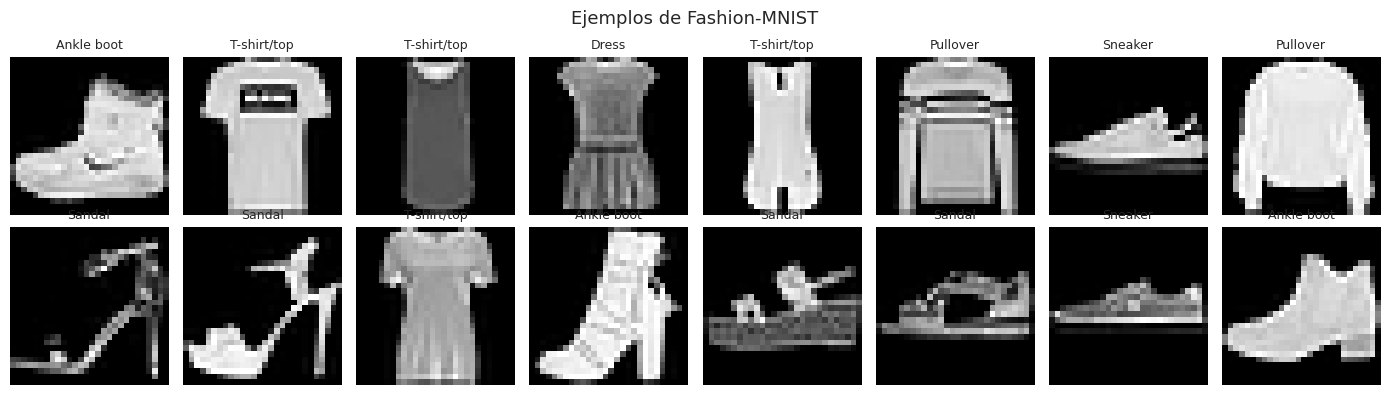

In [ ]:
fig, axes = plt.subplots(1, 8, figsize=(14, 4))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(train_images[i], cmap="gray")
    ax.set_title(class_names[train_labels[i]], fontsize=9)
    ax.axis("off")
plt.suptitle("Ejemplos de Fashion-MNIST", fontsize=13)
plt.tight_layout()
plt.show()

# Preprocesamiento

Pasos:

1. **Normalizar** los píxeles de [0, 255] a [0, 1]. Esto:
   - Acelera la convergencia.
   - Evita que las activaciones iniciales sean demasiado grandes.
2. **Aplanar** cada imagen a un vector de 784 valores (`28 × 28`), porque nuestra red es densa (no convolucional).
3. **Mezclar** el conjunto de entrenamiento. `validation_split=0.2` de Keras toma las **últimas** 20% filas, y como los datos originales están ordenados por clase (el test, no el train; conviene mezclar igual), conviene barajar antes para que la validación sea representativa.

In [ ]:
# 1) Normalización
train_images = train_images.astype("float32") / 255.0
test_images  = test_images.astype("float32")  / 255.0

# 2) Aplanado (28*28 = 784)
train_images_flat = train_images.reshape(-1, 28 * 28)
test_images_flat  = test_images.reshape(-1, 28 * 28)

# 3) Shuffle del conjunto de entrenamiento
rng = np.random.default_rng(42)
perm = rng.permutation(len(train_images_flat))
train_images_flat = train_images_flat[perm]
train_labels      = train_labels[perm]

print("Train flat shape:", train_images_flat.shape)
print("Test  flat shape:", test_images_flat.shape)

Train flat shape: (60000, 784)
Test  flat shape: (10000, 784)


# Construcción del modelo

In [ ]:
def build_model():
    model = keras.Sequential([
        keras.layers.Input(shape=(28 * 28,)),
        keras.layers.Dense(128, activation="relu"),
        keras.layers.Dense(10,  activation="softmax"),
    ])
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

model = build_model()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

# Entrenamiento

In [ ]:
EPOCHS = 50

history = model.fit(
    train_images_flat, train_labels,
    epochs=EPOCHS,
    validation_split=0.2,
    verbose=1,
)

Epoch 1/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.8177 - loss: 0.5182 - val_accuracy: 0.8508 - val_loss: 0.4206
Epoch 2/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8594 - loss: 0.3891 - val_accuracy: 0.8625 - val_loss: 0.3781
Epoch 3/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8740 - loss: 0.3470 - val_accuracy: 0.8700 - val_loss: 0.3574
Epoch 4/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8836 - loss: 0.3202 - val_accuracy: 0.8748 - val_loss: 0.3410
Epoch 5/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8909 - loss: 0.3001 - val_accuracy: 0.8790 - val_loss: 0.3352
Epoch 6/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8954 - loss: 0.2829 - val_accuracy: 0.8836 - val_loss: 0.3247
Epoch 7/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9009 - loss: 0.2695 - val_accuracy: 0.8848 - val_loss: 0.3221
Epoch 8/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9045 - loss: 0.2574 -

# Curvas de loss

**¿Cómo saber cuántas épocas son suficientes?**
- Fíjate en la curva de **loss de validación** (`val_loss`).
- Mientras `val_loss` **baja**, el modelo está aprendiendo.
- Cuando `val_loss` **empieza a subir** mientras `loss` de entrenamiento sigue bajando → **overfitting**.

**Regla práctica:** la época óptima es aquella donde `val_loss` alcanza su **mínimo**. Todo lo que viene después empeora la generalización.

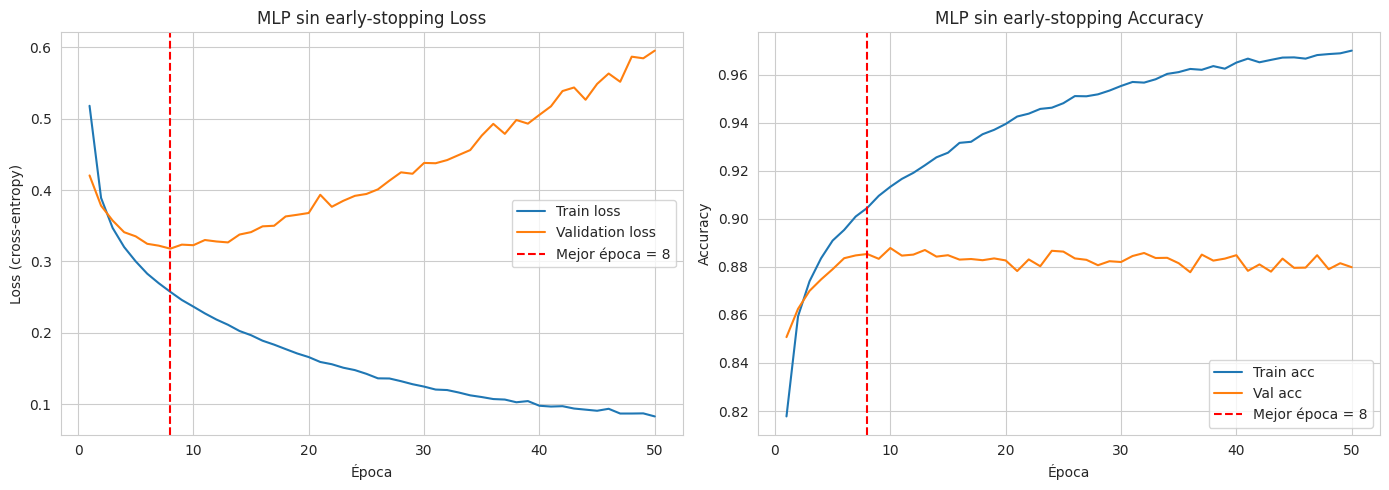

Mejor época según val_loss: 8 (val_loss = 0.3179)


In [ ]:
def plot_history(history, title="") -> int:
    """Grafica loss y accuracy de train vs validación. Devuelve la mejor época (argmin de val_loss)."""
    hist = history.history
    epochs_range = range(1, len(hist["loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # --- Loss ---
    axes[0].plot(epochs_range, hist["loss"],     label="Train loss")
    axes[0].plot(epochs_range, hist["val_loss"], label="Validation loss")
    best_epoch = int(np.argmin(hist["val_loss"])) + 1
    axes[0].axvline(best_epoch, color="red", linestyle="--",
                    label=f"Mejor época = {best_epoch}")
    axes[0].set_xlabel("Época")
    axes[0].set_ylabel("Loss (cross-entropy)")
    axes[0].set_title(f"{title} Loss")
    axes[0].legend()

    # --- Accuracy ---
    axes[1].plot(epochs_range, hist["accuracy"],     label="Train acc")
    axes[1].plot(epochs_range, hist["val_accuracy"], label="Val acc")
    axes[1].axvline(best_epoch, color="red", linestyle="--",
                    label=f"Mejor época = {best_epoch}")
    axes[1].set_xlabel("Época")
    axes[1].set_ylabel("Accuracy")
    axes[1].set_title(f"{title} Accuracy")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

    print(f"Mejor época según val_loss: {best_epoch} "
          f"(val_loss = {hist['val_loss'][best_epoch-1]:.4f})")
    return best_epoch

best_epoch = plot_history(history, "MLP sin early-stopping")

## Lectura del gráfico

Esperamos ver algo así:

- **Train loss** baja monotonamente.
- **Val loss** baja durante N épocas y después empieza a **subir**.
- **Train accuracy** sigue subiendo.
- **Val accuracy** se estanca o baja ligeramente.

La separación entre las dos curvas es la firma del **overfitting**: el modelo memoriza el entrenamiento, pero no generaliza.

**Conclusión didáctica:** con `EarlyStopping` o simplemente guardando el modelo en la mejor época (`best_epoch`), evitamos este problema.

## EarlyStopping

`EarlyStopping` monitorea `val_loss` y **detiene** el entrenamiento cuando no mejora tras `patience` épocas consecutivas. Además, con `restore_best_weights=True` deja el modelo con los pesos de la **mejor** época.

Entrenamos hasta 100 épocas, pero el callback detendrá antes.

Epoch 1/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8177 - loss: 0.5163 - val_accuracy: 0.8507 - val_loss: 0.4196
Epoch 2/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8605 - loss: 0.3858 - val_accuracy: 0.8625 - val_loss: 0.3755
Epoch 3/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8750 - loss: 0.3440 - val_accuracy: 0.8735 - val_loss: 0.3508
Epoch 4/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8831 - loss: 0.3174 - val_accuracy: 0.8766 - val_loss: 0.3340
Epoch 5/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8909 - loss: 0.2983 - val_accuracy: 0.8799 - val_loss: 0.3280
Epoch 6/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8961 - loss: 0.2828 - val_accuracy: 0.8825 - val_loss: 0.3243
Epoch 7/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9008 - loss: 0.2699 - val_accuracy: 0.8858 - val_loss: 0.3159
Epoch 8/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9062 - loss: 

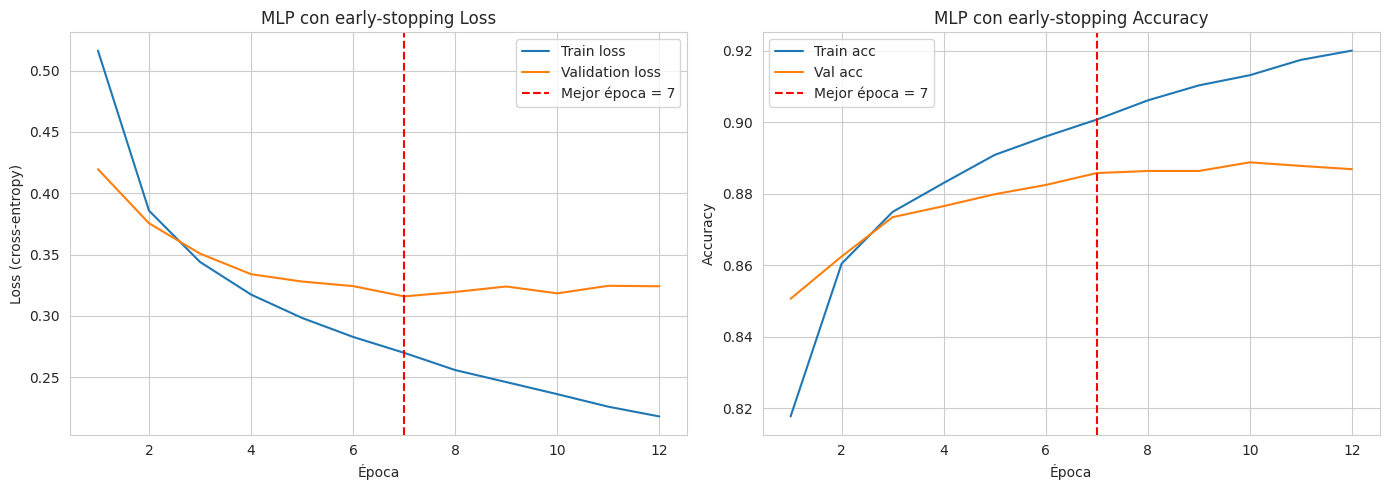

Mejor época según val_loss: 7 (val_loss = 0.3159)


In [ ]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1,
)

model_es = build_model()
history_es = model_es.fit(
    train_images_flat, train_labels,
    epochs=100,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1,
)

plot_history(history_es, "MLP con early-stopping");

#Evaluación en el conjunto de test

**Regla de oro:** el conjunto de **test solo se usa UNA vez**, al final. Lo tocamos únicamente cuando ya hemos elegido el modelo y la época óptima. Usarlo antes para elegir hiperparámetros sería "filtrar información" (leakage).

In [ ]:
test_loss, test_acc = model_es.evaluate(test_images_flat, test_labels, verbose=0)
print(f"Test loss:     {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")

Test loss:     0.3458
Test accuracy: 0.8778


In [ ]:
# Probabilidades por clase (softmax → suma 1 por fila)
y_score = model_es.predict(test_images_flat, verbose=0)
# Etiqueta predicha = clase con mayor probabilidad
y_pred = np.argmax(y_score, axis=1)

print("y_score shape:", y_score.shape, "| y_pred shape:", y_pred.shape)
print("Ejemplo de probabilidades para la primera imagen:")
print({class_names[i]: round(float(p), 3) for i, p in enumerate(y_score[0])})
print("Predicción:", class_names[y_pred[0]], "| Real:", class_names[test_labels[0]])

y_score shape: (10000, 10) | y_pred shape: (10000,)
Ejemplo de probabilidades para la primera imagen:
{'T-shirt/top': 0.0, 'Trouser': 0.0, 'Pullover': 0.0, 'Dress': 0.0, 'Coat': 0.0, 'Sandal': 0.013, 'Shirt': 0.0, 'Sneaker': 0.091, 'Bag': 0.0, 'Ankle boot': 0.896}
Predicción: Ankle boot | Real: Ankle boot


## 8. Métricas de clasificación

Para un problema **multiclase**, las métricas se calculan **por clase** y luego se agregan:

- **Precision**: de lo que el modelo dijo "es de esta clase", ¿cuánto lo era? → `TP / (TP + FP)`.
- **Recall** (sensibilidad): de todas las imágenes que eran de esta clase, ¿cuántas detectó? → `TP / (TP + FN)`.
- **F1-score**: media armónica de precision y recall → `2·P·R / (P + R)`.
- **Support**: cuántas imágenes de esa clase hay en el test.
- **Macro avg**: promedio simple de la métrica por clase (trata todas las clases por igual).
- **Weighted avg**: promedio ponderado por `support` (refleja mejor el desempeño global cuando las clases están desbalanceadas).

              precision    recall  f1-score   support

 T-shirt/top     0.8338    0.8280    0.8309      1000
     Trouser     0.9938    0.9570    0.9750      1000
    Pullover     0.7944    0.7880    0.7912      1000
       Dress     0.8604    0.9000    0.8798      1000
        Coat     0.8020    0.7900    0.7960      1000
      Sandal     0.9630    0.9630    0.9630      1000
       Shirt     0.6911    0.6870    0.6891      1000
     Sneaker     0.9186    0.9590    0.9384      1000
         Bag     0.9541    0.9770    0.9654      1000
  Ankle boot     0.9687    0.9290    0.9484      1000

    accuracy                         0.8778     10000
   macro avg     0.8780    0.8778    0.8777     10000
weighted avg     0.8780    0.8778    0.8777     10000



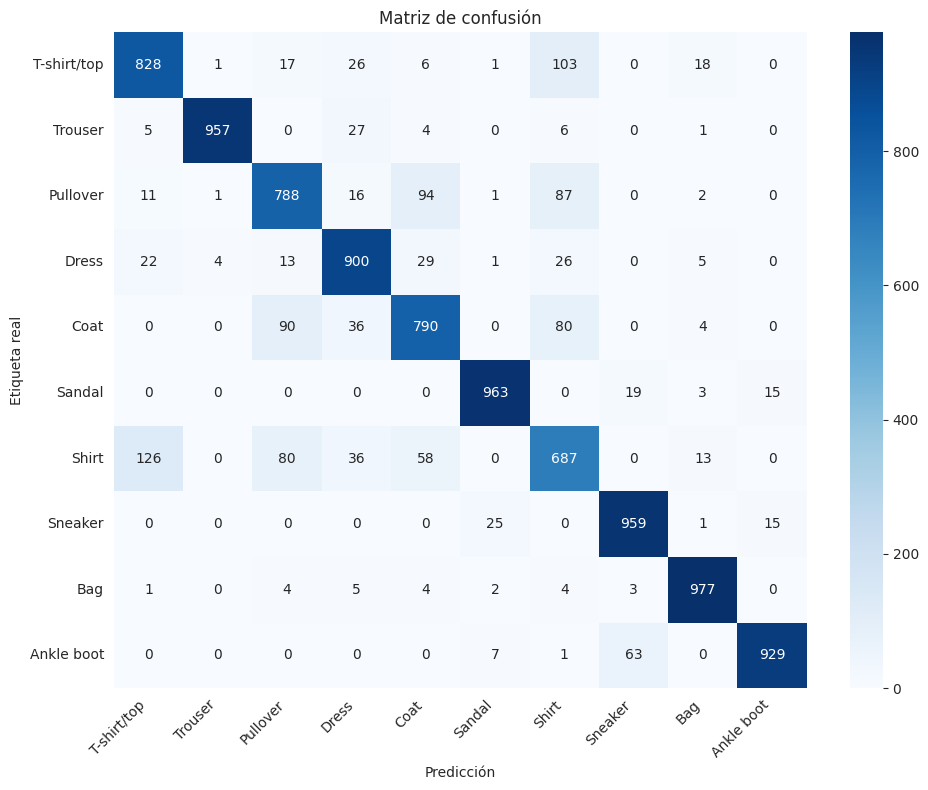

In [ ]:
print(classification_report(test_labels, y_pred, target_names=class_names, digits=4))

cm = confusion_matrix(test_labels, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.title("Matriz de confusión")
plt.xlabel("Predicción")
plt.ylabel("Etiqueta real")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Curva ROC

**ROC = Receiver Operating Characteristic.**

Es una herramienta para **binaria** clasificación, pero se puede adaptar a multiclase con la estrategia *One-vs-Rest*.

## ¿Cómo se construye? (caso binario)

Supón un clasificador que produce un **score** `s ∈ [0, 1]` (aquí, la probabilidad softmax de la clase positiva).

1. **Barrer un umbral** `t` desde 1.0 hasta 0.0.
2. Para cada `t`, clasificar como positivo si `s ≥ t`, negativo si `s < t`.
3. Con la matriz de confusión de ese umbral, calcular:
   - **TPR** (True Positive Rate / Recall) = `TP / (TP + FN)`
   - **FPR** (False Positive Rate)         = `FP / (FP + TN)`
4. Graficar `(FPR, TPR)` para cada `t`. Esa nube de puntos, ordenada por `t`, **es la curva ROC**.

## Lectura de la curva

- `(FPR=0, TPR=0)` → umbral tan alto que nadie es positivo (nada se detecta).
- `(FPR=1, TPR=1)` → umbral tan bajo que todos son positivos.
- Un buen clasificador se pega a la **esquina superior izquierda** (bajo FPR, alto TPR).
- La **diagonal** `TPR = FPR` es el clasificador **aleatorio**.
- **AUC** (Area Under the Curve): área bajo la curva.
  - `AUC = 0.5` → aleatorio.
  - `AUC = 1.0` → perfecto.
  - Interpretación probabilística: `AUC = P(score de un positivo aleatorio > score de un negativo aleatorio)`.

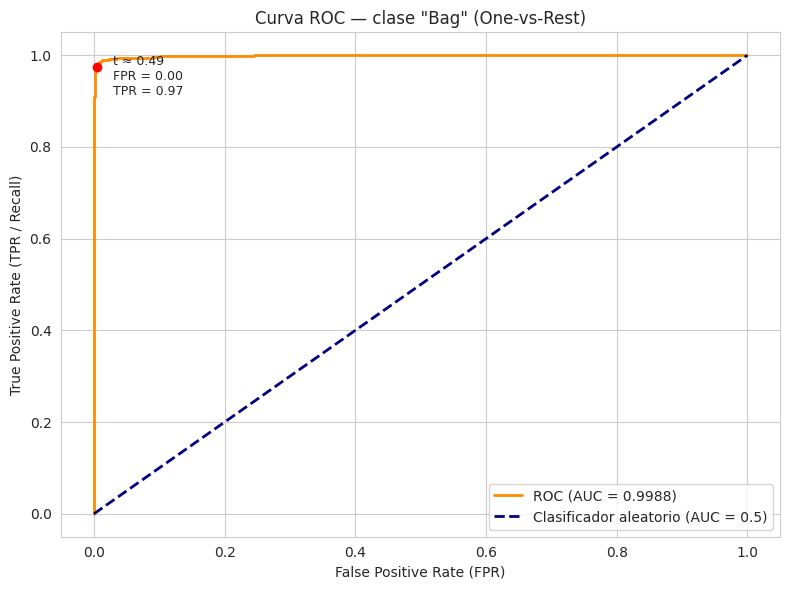

In [ ]:
# Elegimos una clase para ilustrar: "Bag" (índice 8)
class_idx = 8
class_name = class_names[class_idx]

# Binarización: 1 si la imagen es "Bag", 0 si no
y_true_bin  = (test_labels == class_idx).astype(int)
y_score_bin = y_score[:, class_idx]           # probabilidades de la clase

# Cálculo de la curva ROC y el AUC
fpr, tpr, thresholds = roc_curve(y_true_bin, y_score_bin)
roc_auc = auc(fpr, tpr)

# Punto de la curva correspondiente a un umbral cercano a 0.5
idx_05 = int(np.argmin(np.abs(thresholds - 0.5)))

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color="darkorange", lw=2,
         label=f"ROC (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--",
         label="Clasificador aleatorio (AUC = 0.5)")
plt.scatter(fpr[idx_05], tpr[idx_05], color="red", zorder=5)
plt.annotate(
    f"t ≈ {thresholds[idx_05]:.2f}\nFPR = {fpr[idx_05]:.2f}\nTPR = {tpr[idx_05]:.2f}",
    (fpr[idx_05], tpr[idx_05]),
    textcoords="offset points", xytext=(12, -20), fontsize=9,
)
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR / Recall)")
plt.title(f'Curva ROC — clase "{class_name}" (One-vs-Rest)')
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Mostramos algunos umbrales y las métricas correspondientes
# para que los estudiantes vean cómo "se mueve" el punto sobre la curva.
sample_every = max(1, len(thresholds) // 10)
table = pd.DataFrame({
    "Umbral (t)": thresholds[::sample_every],
    "FPR":        fpr[::sample_every],
    "TPR":        tpr[::sample_every],
})
print(table.to_string(index=False))

 Umbral (t)      FPR   TPR
        inf 0.000000 0.000
   0.999998 0.000000 0.483
   0.999995 0.000000 0.535
   0.999984 0.000000 0.591
   0.999925 0.000000 0.682
   0.993147 0.000444 0.876
   0.943129 0.001333 0.936
   0.676049 0.003111 0.970
   0.291231 0.005667 0.981
   0.091912 0.012556 0.989
   0.003078 0.088556 0.997


# ROC para multiclase — One-vs-Rest

Para problemas con K clases, la técnica estándar es **One-vs-Rest (OvR)**:

- Para la clase `k`, se construye un problema **binario**:
  - Positivo = imágenes de la clase `k`.
  - Negativo = todas las demás.
- Se calcula una curva ROC **por cada clase**.
- Se obtiene un **AUC por clase**.

## Agregaciones

- **Micro-average:** se concatenan todas las predicciones y etiquetas binarias de todas las clases y se calcula una sola curva. Favorece a las clases frecuentes.
- **Macro-average:** se **interpolan** todas las curvas a un FPR común y se promedian. Trata todas las clases por igual.

## Por clase

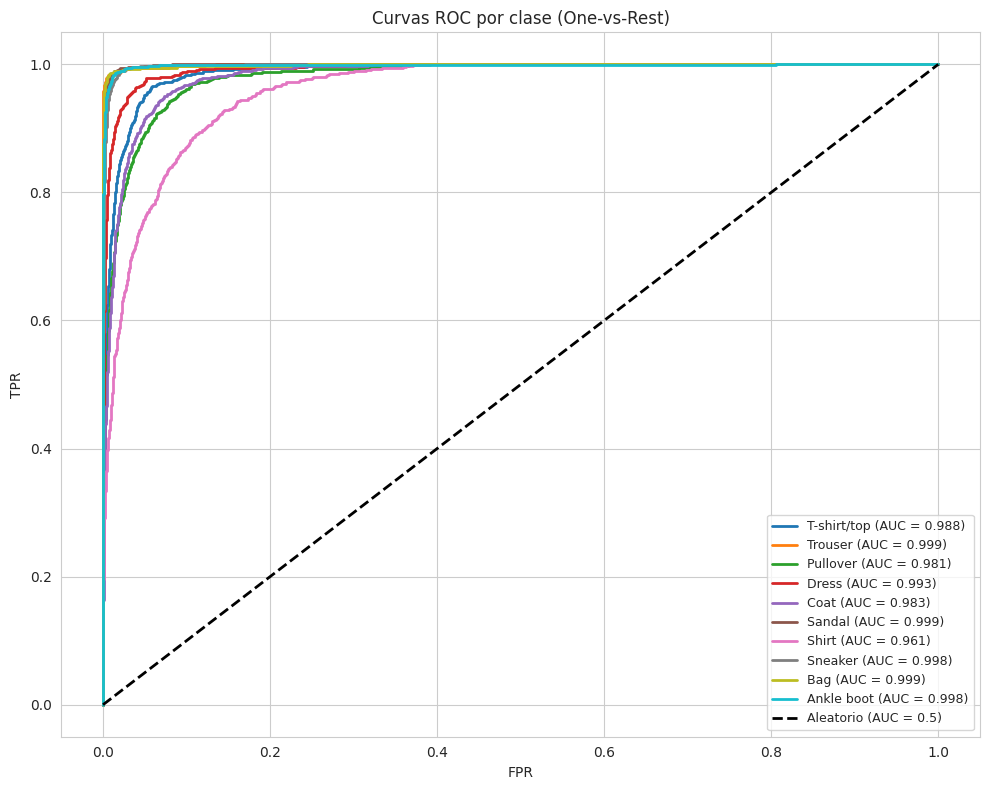

In [ ]:
# Binarización de las etiquetas de test: matriz (n_samples, 10)
y_true_bin_mc = label_binarize(test_labels, classes=list(range(10)))

fpr_dict, tpr_dict, roc_auc_dict = {}, {}, {}

for i in range(10):
    fpr_dict[i], tpr_dict[i], _ = roc_curve(y_true_bin_mc[:, i], y_score[:, i])
    roc_auc_dict[i] = auc(fpr_dict[i], tpr_dict[i])

colors = plt.cm.tab10(np.linspace(0, 1, 10))

plt.figure(figsize=(10, 8))
for i in range(10):
    plt.plot(fpr_dict[i], tpr_dict[i], color=colors[i], lw=2,
             label=f"{class_names[i]} (AUC = {roc_auc_dict[i]:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=2, label="Aleatorio (AUC = 0.5)")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("Curvas ROC por clase (One-vs-Rest)")
plt.legend(loc="lower right", fontsize=9)
plt.grid(True)
plt.tight_layout()
plt.show()

## Promediado

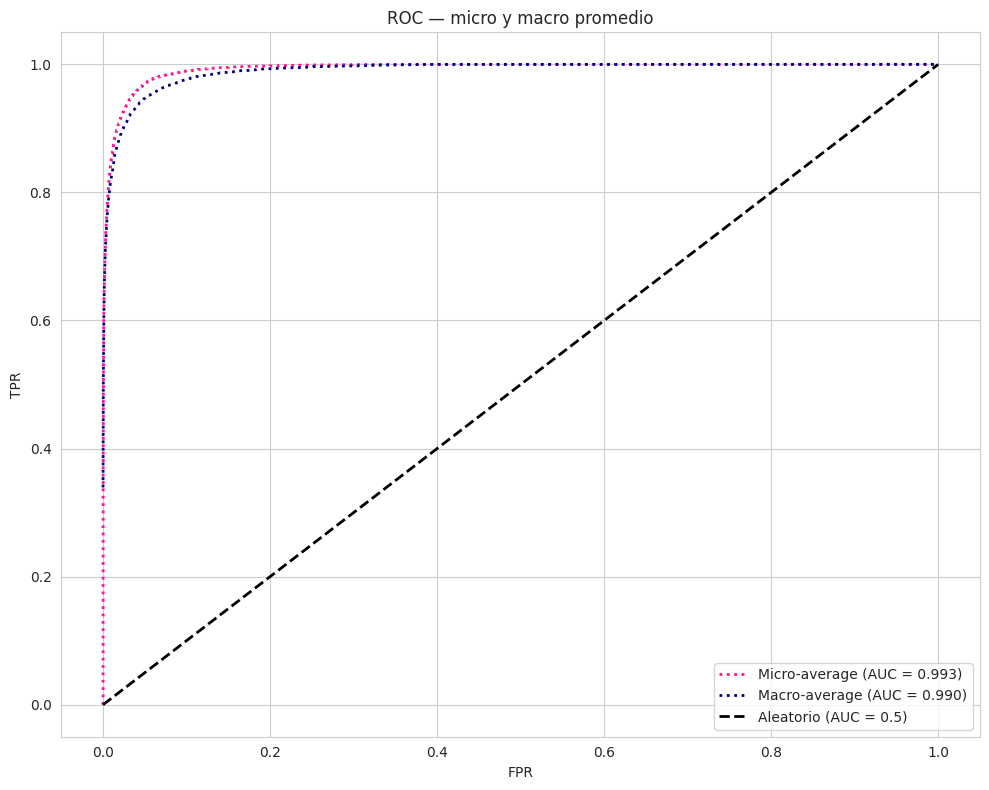

In [ ]:
# Micro-average: se agregan todos los TP, FP, FN y TN de todas las clases
fpr_micro, tpr_micro, _ = roc_curve(y_true_bin_mc.ravel(), y_score.ravel())
roc_auc_micro = auc(fpr_micro, tpr_micro)

# Macro-average: interpolar todas las curvas a una malla común de FPR y promediar
all_fpr = np.unique(np.concatenate([fpr_dict[i] for i in range(10)]))
mean_tpr = np.zeros_like(all_fpr)
for i in range(10):
    mean_tpr += np.interp(all_fpr, fpr_dict[i], tpr_dict[i])
mean_tpr /= 10
roc_auc_macro = auc(all_fpr, mean_tpr)

plt.figure(figsize=(10, 8))
plt.plot(fpr_micro, tpr_micro, color="deeppink", lw=2, linestyle=":",
         label=f"Micro-average (AUC = {roc_auc_micro:.3f})")
plt.plot(all_fpr, mean_tpr, color="navy", lw=2, linestyle=":",
         label=f"Macro-average (AUC = {roc_auc_macro:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=2, label="Aleatorio (AUC = 0.5)")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("ROC — micro y macro promedio")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()